# Motor parameter identification
**Goal:** find two numbers for each motor:
- $T_m$ — how fast the motor reaches its speed (time constant, s)
- $k_e$ — how many volts one rad/s of speed costs (V·s/rad)

**Model of the motor:** $\;T_m\,\dot\omega + \omega = U / k_e$

For a voltage step the wheel angle is $\;\theta(t) = \omega_{ss}\,(t - T_m + T_m e^{-t/T_m})$, where $\omega_{ss} = U/k_e$ is the final speed.

**Data:** `motor_data.txt` from the robot. Each line: `PWM  time_ms  angle_E3  angle_E4  battery`. E3 = wheel 1 (left), E4 = wheel 2 (right).

### Step 1 — Load the data
Read the file, split it into one run per PWM level, and convert to SI units (ms → s, degrees → rad).
The voltage on the motor is $U = PWM/100 \cdot U_{battery}$. The block program could not read the battery, so I enter the value I read on the robot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import odeint

BATTERY = 11.1                                    # V, read on the robot before the run

data = np.loadtxt('motor_data.txt', comments='#')
pwm_list = np.unique(data[:, 0])                  # -100, -95, ..., 100

runs = []
for p in pwm_list:
    rows = data[data[:, 0] == p]                  # all samples of this PWM level
    runs.append({
        'pwm': p,
        'U': p / 100 * BATTERY,                   # voltage, V
        't': rows[:, 1] / 1000,                   # time, s
        'wheel1': np.radians(rows[:, 2]),         # angle, rad
        'wheel2': np.radians(rows[:, 3]),
    })
print(len(runs), 'PWM levels loaded')

41 PWM levels loaded


### Step 2 — Fit the model to every run
For each PWM level and each wheel, `curve_fit` finds the $\omega_{ss}$ and $T_m$ that make the model curve match the measured angle best.

In [2]:
def model(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))

table = []
for r in runs:
    row = {'pwm': r['pwm'], 'U': r['U']}
    for wheel in ('wheel1', 'wheel2'):
        if r['pwm'] == 0:                         # no voltage -> no motion, nothing to fit
            row[wheel] = (0.0, np.nan)
            continue
        t, angle = r['t'], r[wheel] - r[wheel][0]
        guess = [angle[-1] / t[-1], 0.1]          # start: average speed, T_m = 0.1 s
        (w_ss, T_m), _ = curve_fit(model, t, angle, p0=guess, bounds=([-100, 0.001], [100, 2]))
        row[wheel] = (w_ss, T_m)
    table.append(row)

# save the table for the report
lines = ['| PWM, % | U, V | ω_ss wheel 1, rad/s | T_m wheel 1, s | ω_ss wheel 2, rad/s | T_m wheel 2, s |',
         '|---:|---:|---:|---:|---:|---:|']
for row in table:
    (w1, T1), (w2, T2) = row['wheel1'], row['wheel2']
    T1s = '—' if np.isnan(T1) else f'{T1:.3f}'
    T2s = '—' if np.isnan(T2) else f'{T2:.3f}'
    lines.append(f"| {row['pwm']:.0f} | {row['U']:.2f} | {w1:.2f} | {T1s} | {w2:.2f} | {T2s} |")
import os
os.makedirs('report_figs', exist_ok=True)
open('report_figs/table.md', 'w').write('\n'.join(lines) + '\n')
print('\n'.join(lines))

| PWM, % | U, V | ω_ss wheel 1, rad/s | T_m wheel 1, s | ω_ss wheel 2, rad/s | T_m wheel 2, s |
|---:|---:|---:|---:|---:|---:|
| -100 | -11.10 | -14.84 | 0.058 | -14.03 | 0.064 |
| -95 | -10.54 | -14.46 | 0.067 | -13.58 | 0.060 |
| -90 | -9.99 | -13.81 | 0.085 | -12.81 | 0.078 |
| -85 | -9.43 | -13.19 | 0.117 | -12.13 | 0.090 |
| -80 | -8.88 | -12.91 | 0.117 | -11.80 | 0.103 |
| -75 | -8.32 | -12.58 | 0.122 | -11.49 | 0.103 |
| -70 | -7.77 | -11.93 | 0.165 | -10.72 | 0.135 |
| -65 | -7.21 | -11.15 | 0.177 | -9.94 | 0.169 |
| -60 | -6.66 | -10.98 | 0.204 | -9.76 | 0.181 |
| -55 | -6.11 | -10.43 | 0.224 | -9.22 | 0.197 |
| -50 | -5.55 | -10.17 | 0.239 | -8.85 | 0.112 |
| -45 | -5.00 | -9.81 | 0.228 | -8.52 | 0.209 |
| -40 | -4.44 | -9.45 | 0.258 | -8.16 | 0.213 |
| -35 | -3.88 | -9.02 | 0.282 | -7.67 | 0.212 |
| -30 | -3.33 | -7.85 | 0.120 | -6.76 | 0.255 |
| -25 | -2.77 | -7.21 | 0.109 | -6.14 | 0.062 |
| -20 | -2.22 | -6.64 | 0.355 | -5.51 | 0.279 |
| -15 | -1.66 | -5.78 | 0.371 | -4.

### Step 3 — Find $k_e$ and $T_m$ for each wheel
From the model $\omega_{ss} = U / k_e$, so $k_e$ is the slope of the line through zero in the $\omega_{ss}$–$U$ plot.
I use only $|PWM| \ge 30\,\%$, because at low PWM friction makes the motor behave differently.
$T_m$ changes with PWM, so I take the median over the same levels.

wheel1: k_e = 0.653 V·s/rad,  T_m = 0.149 s
wheel2: k_e = 0.705 V·s/rad,  T_m = 0.126 s


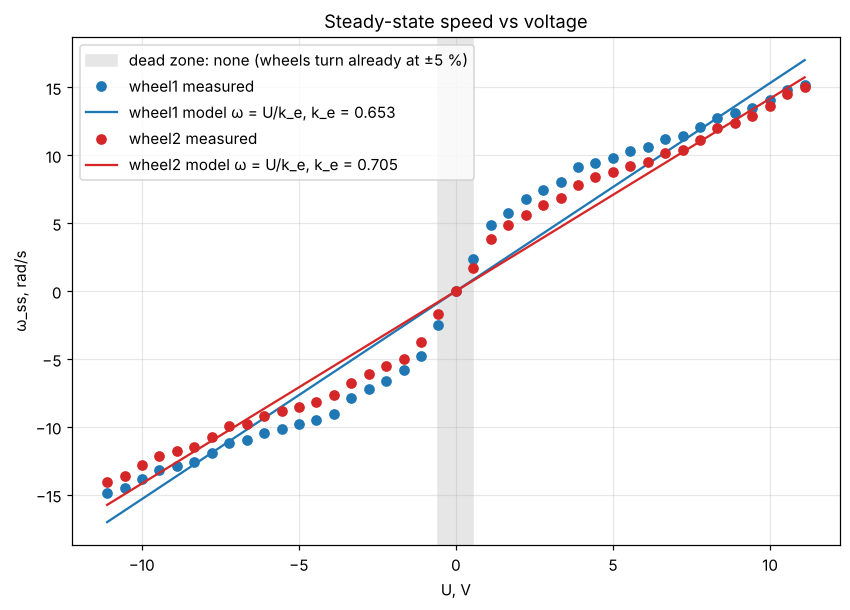

In [3]:
U = np.array([row['U'] for row in table])
pwm = np.array([row['pwm'] for row in table])
use = np.abs(pwm) >= 30

result = {}
for wheel in ('wheel1', 'wheel2'):
    w = np.array([row[wheel][0] for row in table])
    T = np.array([row[wheel][1] for row in table])
    k_e = np.sum(U[use] ** 2) / np.sum(U[use] * w[use])     # least squares, line through 0
    T_m = np.median(T[use])
    result[wheel] = {'k_e': k_e, 'T_m': T_m, 'w': w}
    print(f'{wheel}: k_e = {k_e:.3f} V·s/rad,  T_m = {T_m:.3f} s')

plt.figure(figsize=(9, 6), dpi=110)
plt.axvspan(-0.05 * BATTERY, 0.05 * BATTERY, color='0.9', label='dead zone: none (wheels turn already at ±5 %)')
for wheel, color in (('wheel1', 'tab:blue'), ('wheel2', 'tab:red')):
    k_e = result[wheel]['k_e']
    plt.plot(U, result[wheel]['w'], 'o', color=color, label=f'{wheel} measured')
    plt.plot(U, U / k_e, '-', color=color, label=f'{wheel} model ω = U/k_e, k_e = {k_e:.3f}')
plt.xlabel('U, V'); plt.ylabel('ω_ss, rad/s'); plt.grid(alpha=.3); plt.legend()
plt.title('Steady-state speed vs voltage')
plt.savefig('report_figs/omega_all_wheels.png', bbox_inches='tight')
plt.show()

### Step 4 — Simulate the motor and compare with the measurement
Put the found $T_m$ and $k_e$ into the motor equation, solve it with `odeint`, and plot it next to the real data at PWM = 100 %.

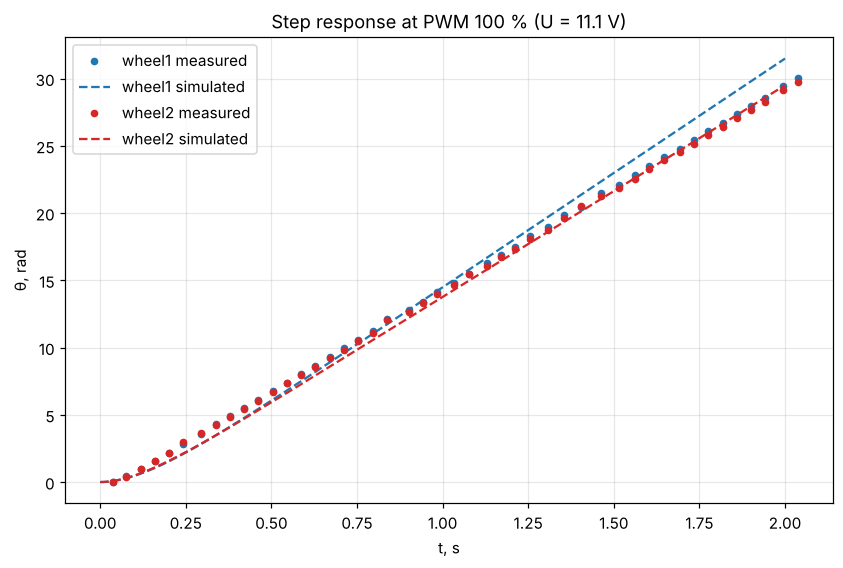

In [4]:
def motor(state, t, U, T_m, k_e):
    w, theta = state
    dw = (U / k_e - w) / T_m          # from T_m * dw/dt + w = U / k_e
    dtheta = w
    return [dw, dtheta]

r = runs[-1]                          # PWM = 100 %
t_sim = np.linspace(0, 2, 200)
plt.figure(figsize=(9, 5.5), dpi=110)
for wheel, color in (('wheel1', 'tab:blue'), ('wheel2', 'tab:red')):
    p = result[wheel]
    theta_sim = odeint(motor, [0, 0], t_sim, args=(r['U'], p['T_m'], p['k_e']))[:, 1]
    plt.plot(r['t'], r[wheel] - r[wheel][0], 'o', color=color, ms=4, label=f'{wheel} measured')
    plt.plot(t_sim, theta_sim, '--', color=color, label=f'{wheel} simulated')
plt.xlabel('t, s'); plt.ylabel('θ, rad'); plt.grid(alpha=.3); plt.legend()
plt.title(f'Step response at PWM 100 % (U = {r["U"]:.1f} V)')
plt.savefig('report_figs/step_response.png', bbox_inches='tight')
plt.show()

### Step 5 — How different are the two wheels?
Same PWM on both wheels, compare their speeds.

In [5]:
for p in (100, 50, 10):
    i = list(pwm).index(p)
    w1, w2 = result['wheel1']['w'][i], result['wheel2']['w'][i]
    print(f'PWM {p:3d} %: wheel1 = {w1:.2f}, wheel2 = {w2:.2f} rad/s  -> wheel1 is {100 * (w1 - w2) / w2:.0f} % faster')

PWM 100 %: wheel1 = 15.19, wheel2 = 15.02 rad/s  -> wheel1 is 1 % faster
PWM  50 %: wheel1 = 10.30, wheel2 = 9.23 rad/s  -> wheel1 is 12 % faster
PWM  10 %: wheel1 = 4.88, wheel2 = 3.86 rad/s  -> wheel1 is 26 % faster
